# EuroSAT: four-class manifest benchmark

Compare ResNet-18, ConvNeXt-Tiny, ViT-B/16 and DINOv2 on the **same fixed four-way episodes**. Six base classes are reserved; four novel classes are evaluated. Backbones stay frozen, and logistic regression is fitted on support embeddings.

The workflow is: **1–2 setup → 3 inspect and validate data → 4 inspect model contracts → 5 execute → 6 inspect each model → 7 compare with ResNet**. Smoke runs verify execution; they are not research conclusions. Start in smoke mode.

Colab needs the project source: copy `src/` into `<shared storage>/code/src/`, or set `EUROSAT_CODE_DIR` to a repository checkout. Copy the committed `splits_manifest.json` into shared storage. Locally, open this notebook from the repository and select its Python environment.


## 1. Choose the run

These settings choose hardware, model subset and episode budget. No models or data are loaded yet. Smoke uses the first two development and two test episodes at each shot setting; full uses all 100 development and 600 test episodes. The manifest is always validated in full.


In [1]:
import os
import sys
import subprocess
from pathlib import Path

TARGET = os.environ.get('EUROSAT_TARGET', 'colab_gpu')  # local for a local VS Code kernel.
MODE = os.environ.get('EUROSAT_MODE', 'smoke')
MODELS = os.environ.get('EUROSAT_MODELS', 'all')
STORAGE_OVERRIDE = os.environ.get('EUROSAT_STORAGE', '')
CODE_DIR = os.environ.get('EUROSAT_CODE_DIR', '')
MANIFEST_FILE = os.environ.get('EUROSAT_SPLITS', '')
REPORT_RESULTS = os.environ.get('EUROSAT_REPORT_RESULTS', '')
REPORT_ONLY = bool(REPORT_RESULTS)

if TARGET not in {'local', 'colab_gpu'} or MODE not in {'smoke', 'full'}:
    raise ValueError('Choose TARGET local/colab_gpu and MODE smoke/full')


## 2. Connect storage and import the implementation

The shared Drive folder stores the verified ZIP, weights, embeddings, validation exports and results. Extracted JPEGs stay on local scratch storage. Keep one writer per shared experiment; atomic files are not a distributed Drive lock.

The source directory contains code only. Package imports below do not load pretrained weights. Source changes require restarting the kernel; changing this notebook does not require copying implementations into cells.


In [2]:
import importlib.util

requirements = {'torch': 'torch>=2.6,<3', 'torchvision': 'torchvision>=0.21,<1',
                'numpy': 'numpy>=1.26,<3', 'sklearn': 'scikit-learn>=1.4,<1.8',
                'PIL': 'Pillow>=10,<13', 'pandas': 'pandas>=2.2,<3',
                'matplotlib': 'matplotlib>=3.8,<4', 'seaborn': 'seaborn>=0.13,<0.14'}
missing = [package for module, package in requirements.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '--quiet', *missing])

if TARGET == 'colab_gpu':
    from google.colab import drive
    drive.mount('/content/drive')
    parent = Path('/content/drive/MyDrive/ColabNotebooks/cs7643')
    default = parent / 'EuroSATLowData' if (parent / 'EuroSATLowData').exists() else parent / 'EuroSATRepresentationBenchmark'
    STORAGE = Path(STORAGE_OVERRIDE or default)
    if STORAGE_OVERRIDE and not STORAGE.is_dir():
        raise FileNotFoundError('Shared storage is unavailable: check the My Drive shortcut and EUROSAT_STORAGE')
    SCRATCH = Path('/content/eurosat-representation-benchmark')
else:
    current = Path.cwd()
    project = next((p for p in [current, *current.parents] if (p / 'pyproject.toml').exists()), current)
    STORAGE = Path(STORAGE_OVERRIDE or project)
    SCRATCH = STORAGE / 'data/extracted'

STORAGE.mkdir(parents=True, exist_ok=True)
candidates = [Path(CODE_DIR)] if CODE_DIR else [Path.cwd(), *Path.cwd().parents, Path('/content/eurosat-representation-benchmark'), STORAGE / 'code']
source_root = next((p for p in candidates if (p / 'src/eurosat/__init__.py').is_file()), None)
if source_root is None:
    raise FileNotFoundError('Set EUROSAT_CODE_DIR to the repository, or copy src/ into <storage>/code/src/')
sys.path.insert(0, str(source_root / 'src'))

print('Persistent storage:', STORAGE)
print('Local extracted images:', SCRATCH)
print('Project source:', source_root)


Persistent storage: /Users/ericsheng495/Desktop/eurosat-representation-benchmark
Local extracted images: /Users/ericsheng495/Desktop/eurosat-representation-benchmark/data/extracted
Project source: /Users/ericsheng495/Desktop/eurosat-representation-benchmark


In [3]:
import json
import pandas as pd
from IPython.display import display, Image as NotebookImage

from eurosat.config import Config, MODEL_IDS
from eurosat.experiments import manifest_config, run_manifest_benchmark
from eurosat.models import EMBEDDING_DIMENSIONS
from eurosat.preprocessing import load_source, validate_manifest, select_episodes
from eurosat.preprocessing.audit import episode_table, usage_table, inspect_batch, data_figures
from eurosat.reporting import create_report, display_model_evaluation, baseline_comparison
from eurosat.evaluation import summarize
from eurosat.runtime import check_device, environment

config = manifest_config(MODE, MODELS)
if os.environ.get('EUROSAT_TRIALS'):
    config.trials = int(os.environ['EUROSAT_TRIALS'])
if os.environ.get('EUROSAT_POLICIES'):
    config.policies = os.environ['EUROSAT_POLICIES'].split(',')
if os.environ.get('EUROSAT_VIEWS'):
    config.views = int(os.environ['EUROSAT_VIEWS'])
if REPORT_ONLY:
    saved = json.loads(Path(REPORT_RESULTS).read_text())
    if 'episode_source' not in saved['manifest']:
        raise ValueError('This notebook expects four-class manifest results')
    config = Config(**saved['manifest']['config'])
config.validate()

manifest_path = Path(MANIFEST_FILE) if MANIFEST_FILE else STORAGE / 'splits_manifest.json'
device = None if REPORT_ONLY else check_device(TARGET)
print('Run:', config.mode, '| models:', config.models, '| shots:', config.shots)
print('Test episodes per shot:', config.trials, '| policies:', config.policies)
print('Software:', environment())


Compute: mps [mps] — device check passed


Run: smoke | models: ['resnet18', 'convnext_tiny', 'vit_b_16', 'dinov2_vits14'] | shots: [1, 5, 10]
Test episodes per shot: 2 | policies: ['none']
Software: {'torch': '2.8.0', 'torchvision': '0.23.0', 'numpy': '2.4.6', 'sklearn': '1.7.2'}


## 3. Data processing: inspect each stage

No split is generated here. The committed manifest is the contract for which images may enter development and final evaluation. The following stages expose the source inventory, all-pool checks and selected episode assignments before inference starts.

### 3.1 Verify the source archive and local images

`load_source()` verifies the ZIP checksum, checks each extracted file against its ZIP CRC, and restores missing/changed local files from that ZIP. The cached decoded-RGB audit checks image decoding and exact pixel duplicates; conflicting labels or undecodable images stop the run. The table distinguishes all ten source classes from the four evaluated classes.


In [4]:
if REPORT_ONLY:
    print('Report only: source acquisition is skipped.')
else:
    source = load_source(STORAGE, SCRATCH, config.seed)

    display(pd.DataFrame(source.inventory))
    display(pd.Series(source.integrity, name='source_check').to_frame())
    print('Native image properties:', source.properties)
    print('Source audit:', source.audit_path)


Source audit: 27,000 files verified; 0 restored; 0 exact-pixel duplicates


,class,role,archive_images,unique_images
0,AnnualCrop,base (reserved),3000,3000
1,Forest,base (reserved),3000,3000
2,HerbaceousVegetation,novel (evaluated),3000,3000
3,Highway,base (reserved),2500,2500
4,Industrial,base (reserved),2500,2500
5,Pasture,novel (evaluated),2000,2000
6,PermanentCrop,novel (evaluated),2500,2500
7,Residential,base (reserved),3000,3000
8,River,novel (evaluated),2500,2500
9,SeaLake,base (reserved),3000,3000


,source_check
archive_md5_verified,True
files_crc_verified,27000
missing_or_changed_files_restored,0
decoded_pixel_duplicates,0
corrupt_images,0


Native image properties: {'native_sizes': {'64x64': 27000}, 'color_modes': {'RGB': 27000}}
Source audit: /Users/ericsheng495/Desktop/eurosat-representation-benchmark/cache/dataset-8ebea626349354c5328b142b96d0430e647051f26efc2dc974c843f25ecf70bd.json


### 3.2 Validate the entire shared manifest

`validate_manifest()` checks complete file coverage, unique class-pool membership, development/test isolation by filenames **and decoded pixels**, and correct support/query sizes and separation in **every committed episode**. Smoke mode does not weaken these checks.

The six base classes are reserved. Novel development labels are extra selection information outside the support-shot budget. Novel test queries never choose C, augmentation settings or model checkpoints.


In [5]:
if not REPORT_ONLY:
    validated = validate_manifest(manifest_path, source)

    print('Manifest SHA256:', validated.sha256)
    display(pd.DataFrame(validated.pools))
    display(pd.DataFrame(validated.episode_counts))
    display(pd.DataFrame(validated.checks))


Manifest SHA256: 6d8be20440abca33e06f2e2ebc51d4551ccfe30c521bbd872b80bafb1398bb77


,class,role,pool,images
0,AnnualCrop,base (reserved),train,1800
1,AnnualCrop,base (reserved),val,600
2,AnnualCrop,base (reserved),test,600
3,Forest,base (reserved),train,1800
4,Forest,base (reserved),val,600
5,Forest,base (reserved),test,600
6,HerbaceousVegetation,novel,dev_pool,900
7,HerbaceousVegetation,novel,test_pool,2100
8,Highway,base (reserved),train,1500
9,Highway,base (reserved),val,500


,phase,shots,episodes,support_per_episode,query_per_episode
0,dev,1,100,4,60
1,dev,5,100,20,60
2,dev,10,100,40,60
3,test,1,600,4,60
4,test,5,600,20,60
5,test,10,600,40,60


,check,result
0,"Class order, shot budgets and query count",passed
1,Full image coverage and unique pool membership,passed
2,Development/test filename and decoded-pixel is...,passed
3,Support/query separation in every committed ep...,passed


### 3.3 Select the run's fixed episodes and export their lineage

`select_episodes()` takes the first configured episodes without shuffling or resampling. It resolves filenames to stable image indices and saves the source checks, manifest fingerprint, exact record list and exact selected episode indices under `cache/data-audits/`.

The usage table makes repeated image use visible. Query images can recur across episodes; these are repeated observations, not additional independently labeled images. The example table shows the actual 5-shot development support/query assignments.


In [6]:
if not REPORT_ONLY:
    prepared = select_episodes(source, validated, config, STORAGE)

    display(usage_table(prepared))
    display(episode_table(prepared, phase='dev', shots=5, episode=0))
    print('Unique images selected for this run:', len(prepared.records))
    print('Inspect exported records, episodes and checks:', prepared.audit_dir)


,phase,shots,role,episodes,image_assignments,unique_images,maximum_reuse
0,dev,1,support,2,8,8,1
1,dev,1,query,2,120,120,1
2,dev,5,support,2,40,40,1
3,dev,5,query,2,120,120,1
4,dev,10,support,2,80,78,2
5,dev,10,query,2,120,120,1
6,test,1,support,2,8,8,1
7,test,1,query,2,120,120,1
8,test,5,support,2,40,40,1
9,test,5,query,2,120,119,2


,phase,episode,role,class,path
0,dev,0,support,HerbaceousVegetation,HerbaceousVegetation/HerbaceousVegetation_2085...
1,dev,0,support,HerbaceousVegetation,HerbaceousVegetation/HerbaceousVegetation_2479...
2,dev,0,support,HerbaceousVegetation,HerbaceousVegetation/HerbaceousVegetation_715.jpg
3,dev,0,support,HerbaceousVegetation,HerbaceousVegetation/HerbaceousVegetation_819.jpg
4,dev,0,support,HerbaceousVegetation,HerbaceousVegetation/HerbaceousVegetation_501.jpg
...,...,...,...,...,...
75,dev,0,query,River,River/River_537.jpg
76,dev,0,query,River,River/River_2014.jpg
77,dev,0,query,River,River/River_1314.jpg
78,dev,0,query,River,River/River_436.jpg


Unique images selected for this run: 927
Inspect exported records, episodes and checks: /Users/ericsheng495/Desktop/eurosat-representation-benchmark/cache/data-audits/6d8be20440abca33e06f2e2ebc51d4551ccfe30c521bbd872b80bafb1398bb77/88d01c229a043a3e48e077cf2460ec98626a1b1389df9d861b0c902b281a78c2


### 3.4 Inspect model inputs and development support examples

The same Dataset converts images to RGB, resizes bilinearly to 224×224 and applies ImageNet channel normalization. Development/query reads are deterministic. The check prints tensor shape, dtype, finite-value status and repeated-read equality. Normalized values need not lie between zero and one.

The montage uses development **support** images from episode 0, never test images or high-scoring examples. The pool chart shows the manifest's actual development/test allocation.


,input_check
batch_shape,"[4, 3, 224, 224]"
dtype,torch.float32
labels,"[2, 5, 6, 8]"
finite,True
deterministic,True
range_after_normalization,"[-1.7069098949432373, 1.7694151401519775]"


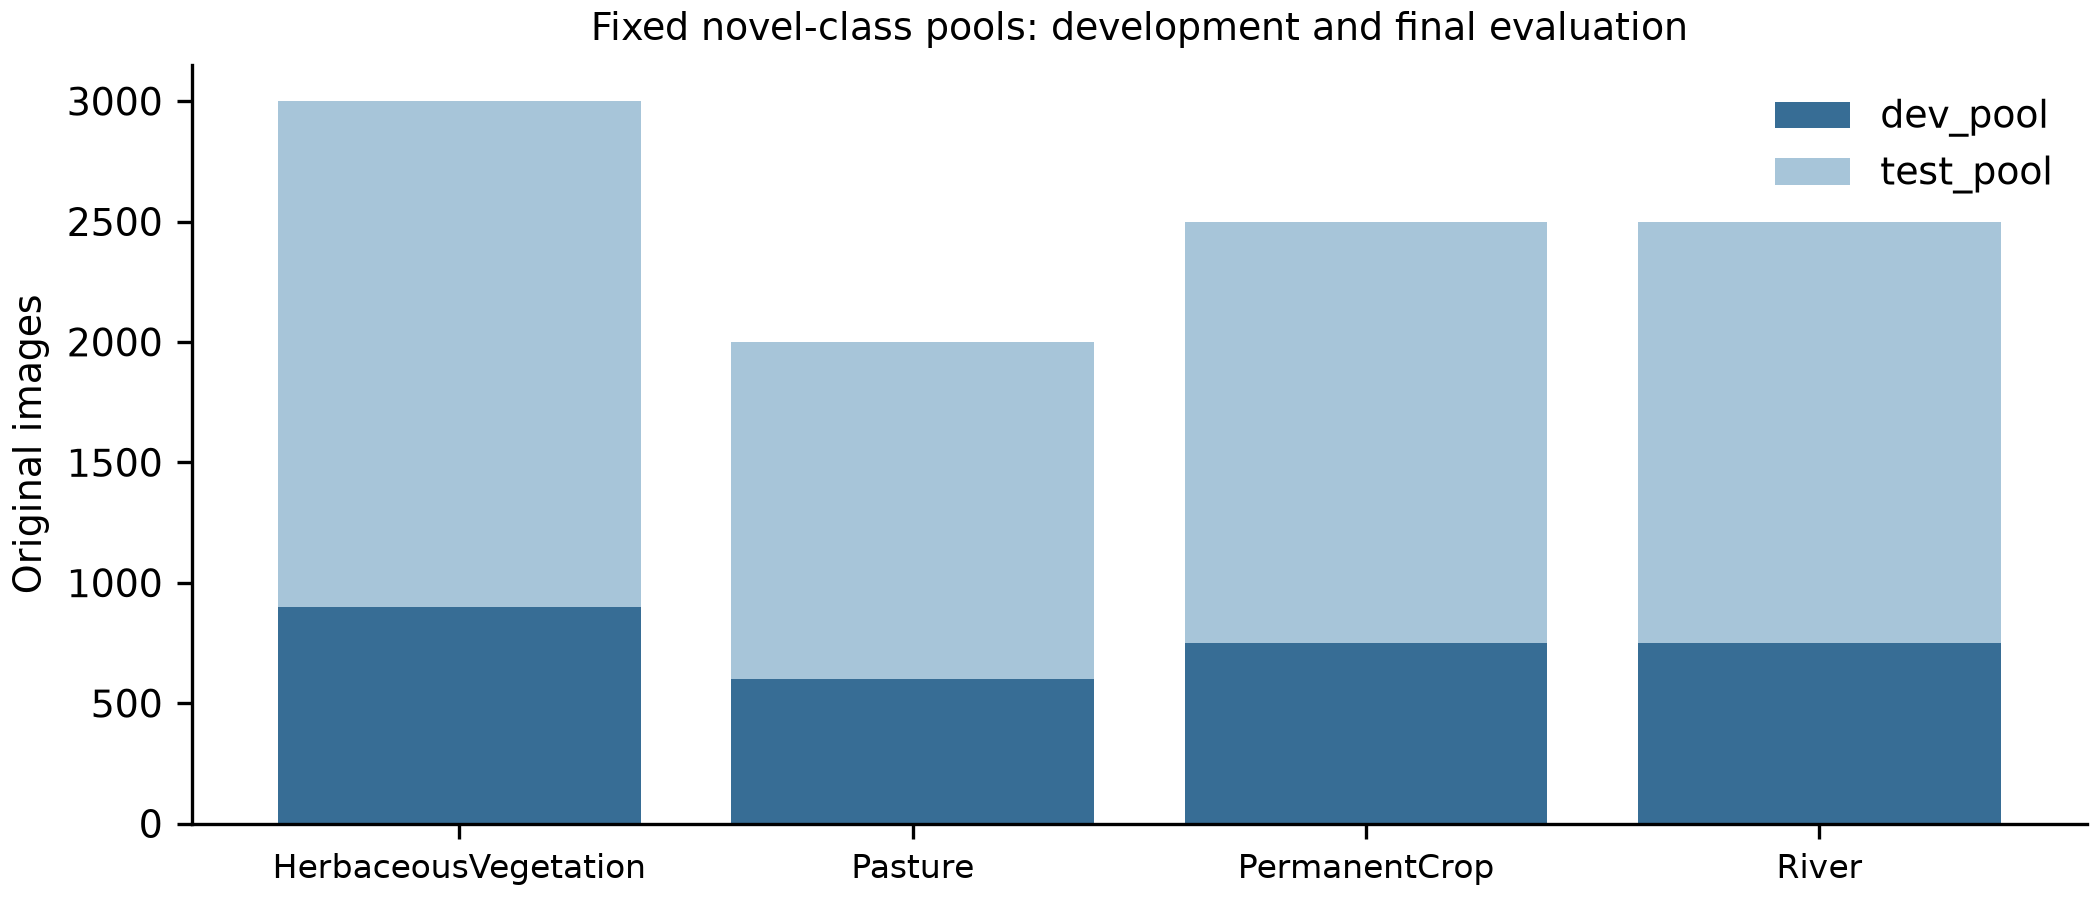

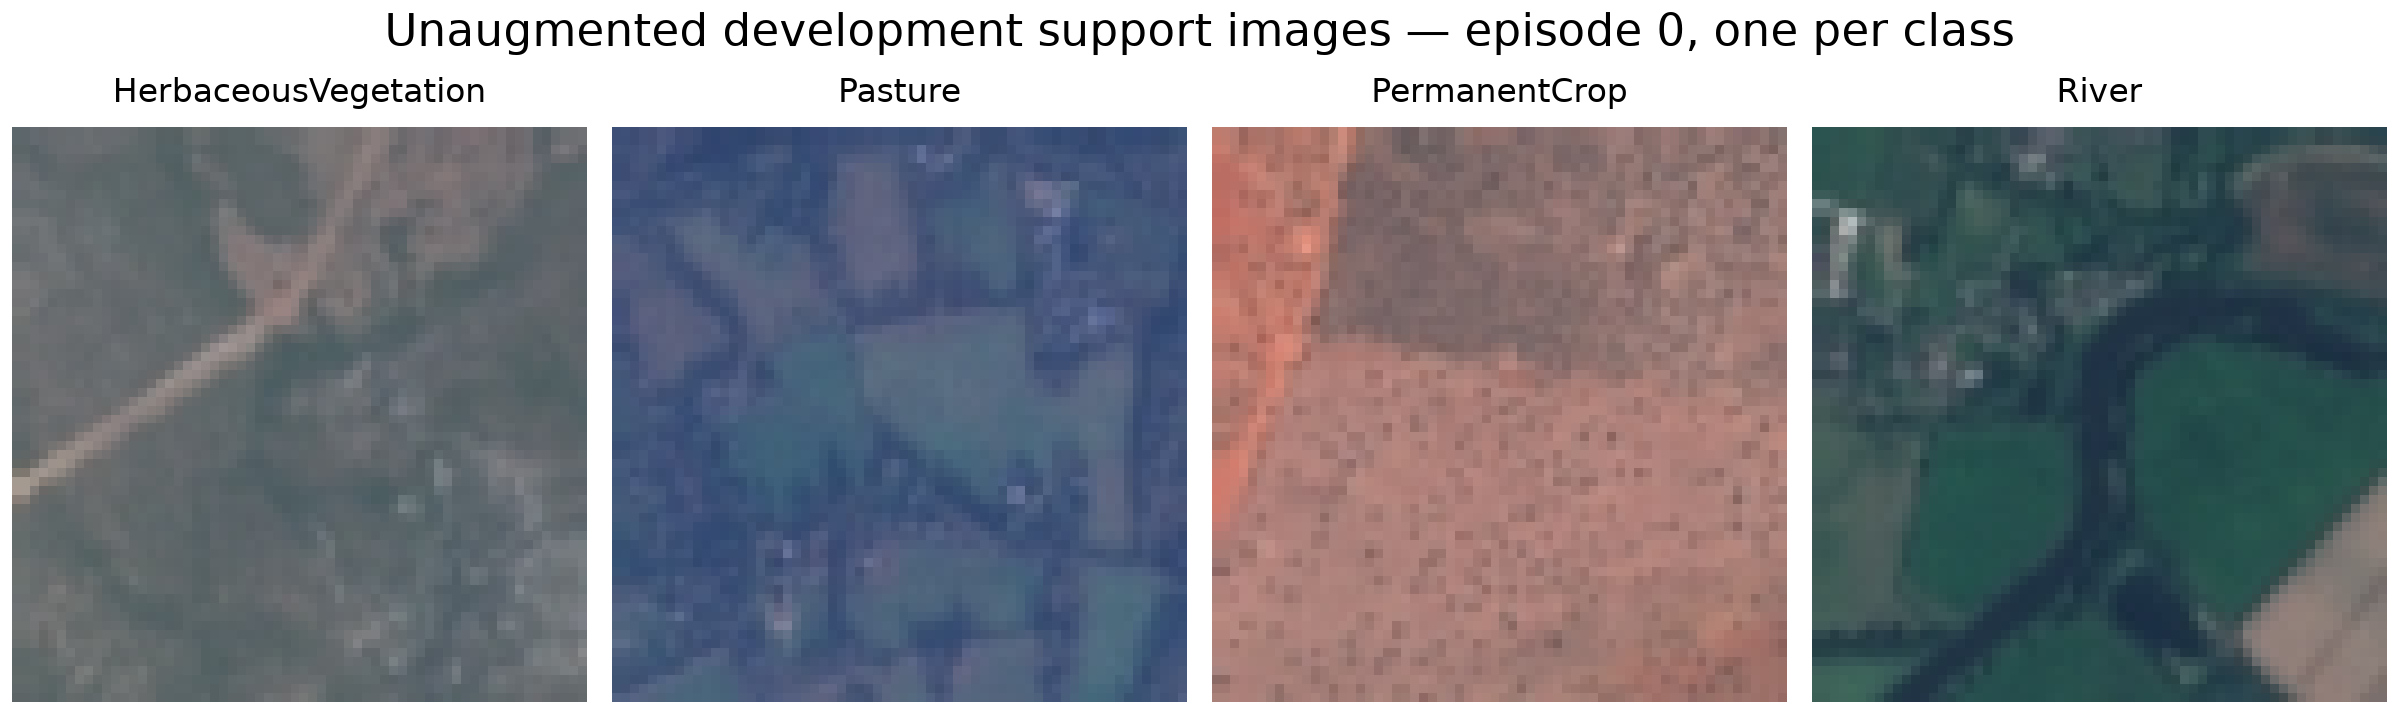

In [7]:
if not REPORT_ONLY:
    display(pd.Series(inspect_batch(prepared, config), name='input_check').to_frame())

    data_plots = data_figures(prepared, validated)
    for filename in data_plots.values():
        display(NotebookImage(filename=filename, width=850))


## 4. Model implementation map

Each teammate edits one adapter in `src/eurosat/models/`. `build()` must return a pretrained network with its classification head removed. The shared loader freezes weights and sets evaluation mode; the shared feature extractor checks embedding width and finite values.

Do not add private splitting, preprocessing or classifier code inside an adapter. ResNet-18 is the baseline. Updating weights or extraction semantics requires updating the checkpoint/cache identity before reusing embeddings.


In [8]:
display(pd.DataFrame([{'model': name,
                       'implementation': f'src/eurosat/models/{name}.py',
                       'embedding_width': EMBEDDING_DIMENSIONS[name],
                       'checkpoint': MODEL_IDS[name],
                       'included': name in config.models}
                      for name in MODEL_IDS]))


,model,implementation,embedding_width,checkpoint,included
0,resnet18,src/eurosat/models/resnet18.py,512,torchvision.ResNet18_Weights.IMAGENET1K_V1,True
1,convnext_tiny,src/eurosat/models/convnext_tiny.py,768,torchvision.ConvNeXt_Tiny_Weights.IMAGENET1K_V1,True
2,vit_b_16,src/eurosat/models/vit_b_16.py,768,torchvision.ViT_B_16_Weights.IMAGENET1K_V1,True
3,dinov2_vits14,src/eurosat/models/dinov2_vits14.py,384,facebookresearch/dinov2:7764ea0f912e53c92e82eb...,True


## 5. Run or resume the four-model evaluation

This call consumes the already inspected `prepared` episodes. Models execute sequentially; each is released before the next is loaded. Matching chunks and completed trials are reused. Missing classifiers use development episodes to choose C, then fit each test episode's support set and predict only its query set. No backbone training occurs.

The shared classifier is L2-regularized logistic regression on L2-normalized embeddings, with C in `[0.1, 1, 10]`. Augmentation, if enabled, is support-only with fixed strengths. JSON/CSV, numeric classifier checkpoints and timings are saved under the printed experiment directory.


In [9]:
if REPORT_ONLY:
    result_path = Path(REPORT_RESULTS)
    results = {'output': str(result_path.parent), 'summary': summarize(saved['trials']),
               'report': create_report(result_path, os.environ.get('EUROSAT_REPORT_OUTPUT'))}
else:
    results = run_manifest_benchmark(config, STORAGE, SCRATCH, manifest_path,
                                    target=TARGET, episode_limit=config.trials, prepared=prepared)

print('Saved model results:', results['output'])


Compute: mps [mps] — device check passed


CACHE HIT experiment 7b7f585609eb29506decccd73d70807375d37948e81b7542996ac98734f81488 model resnet18: 6/6 completed trials


Completed results reused: resnet18


CACHE HIT experiment 7b7f585609eb29506decccd73d70807375d37948e81b7542996ac98734f81488 model convnext_tiny: 6/6 completed trials


Completed results reused: convnext_tiny


CACHE HIT experiment 7b7f585609eb29506decccd73d70807375d37948e81b7542996ac98734f81488 model vit_b_16: 6/6 completed trials


... (2 outputs left out)

Completed results reused: dinov2_vits14


Finished. Results: /Users/ericsheng495/Desktop/eurosat-representation-benchmark/outputs/7b7f585609eb29506decccd73d70807375d37948e81b7542996ac98734f81488


Result figures and tables: /Users/ericsheng495/Desktop/eurosat-representation-benchmark/outputs/7b7f585609eb29506decccd73d70807375d37948e81b7542996ac98734f81488/report


Saved model results: /Users/ericsheng495/Desktop/eurosat-representation-benchmark/outputs/7b7f585609eb29506decccd73d70807375d37948e81b7542996ac98734f81488


## 6. Inspect each model

These cells read saved predictions and metrics; they do not rerun inference. Each shows mean accuracy/Macro-F1, development-selected C, episode count, per-class recall and a normalized confusion matrix at the largest shot budget without augmentation. A model excluded from `MODELS` is explicitly marked as not run. Smoke scores are execution checks only.


### 6.1 ResNet-18 — baseline

A standard CNN. Use its paired results as the reference for the other three backbones.

,,accuracy,macro_f1,episodes,dev_accuracy,selected_C,mean_fit_seconds
shots,policy,,,,,,
1,none,0.6167,0.5987,2,0.6667,10.0,0.0015
5,none,0.9083,0.9097,2,0.8333,10.0,0.0030
10,none,0.8417,0.8422,2,0.9167,10.0,0.0038


,class_recall
HerbaceousVegetation,0.9333
Pasture,0.7667
PermanentCrop,0.8000
River,0.8667


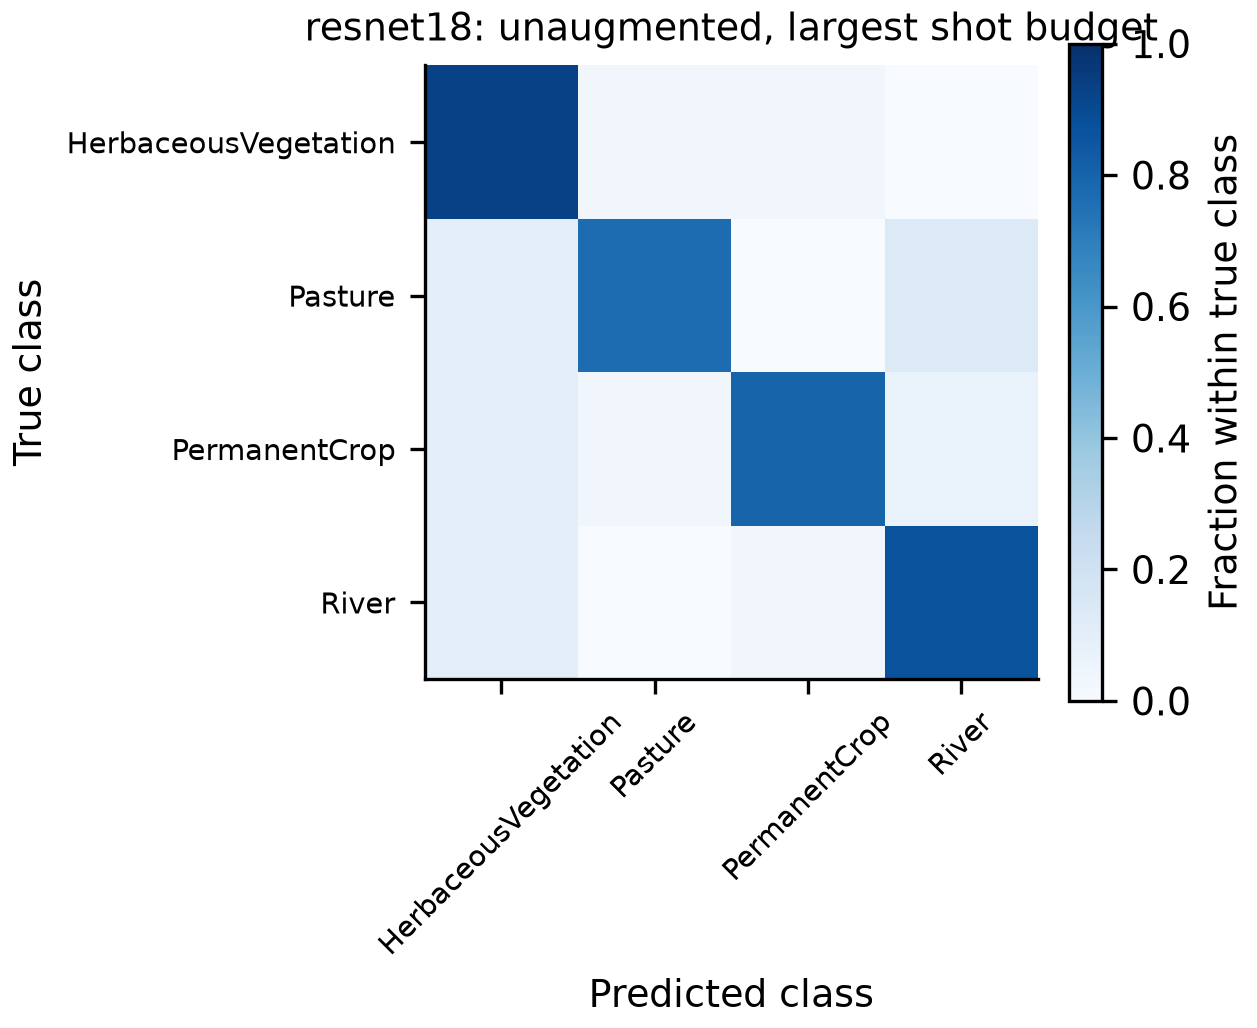

In [10]:
display_model_evaluation(results, 'resnet18')


### 6.2 ConvNeXt-Tiny

A modern CNN. Compare it with ResNet on the same images and classifier procedure.

,,accuracy,macro_f1,episodes,dev_accuracy,selected_C,mean_fit_seconds
shots,policy,,,,,,
1,none,0.6333,0.6230,2,0.7083,0.1,0.0012
5,none,0.9000,0.9026,2,0.7833,10.0,0.0031
10,none,0.8250,0.8255,2,0.9083,10.0,0.0041


,class_recall
HerbaceousVegetation,0.9000
Pasture,0.8667
PermanentCrop,0.7333
River,0.8000


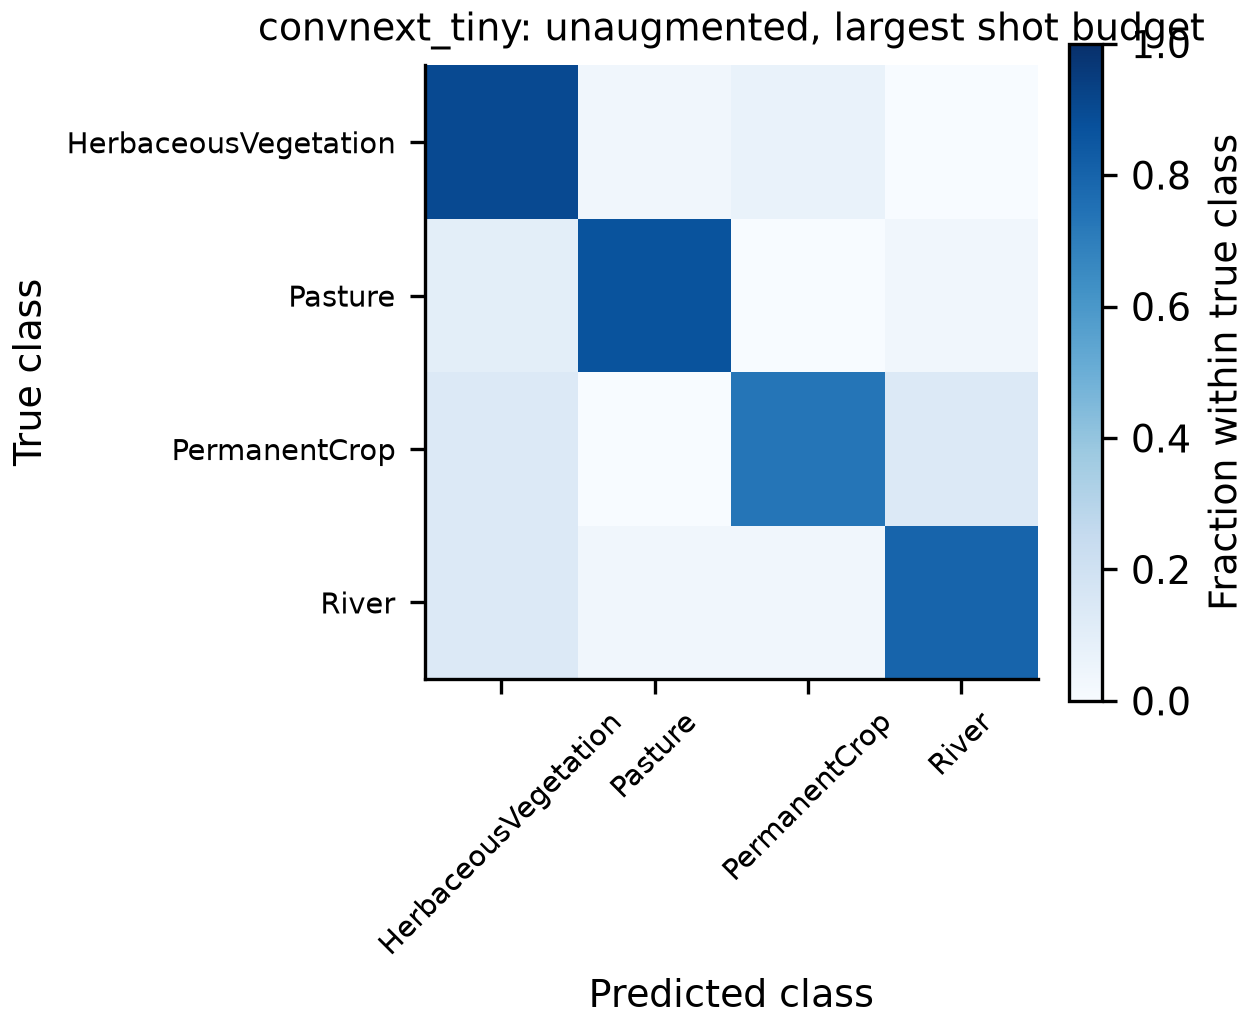

In [11]:
display_model_evaluation(results, 'convnext_tiny')


### 6.3 ViT-B/16

A supervised Vision Transformer. Its adapter returns the final class-token embedding.

,,accuracy,macro_f1,episodes,dev_accuracy,selected_C,mean_fit_seconds
shots,policy,,,,,,
1,none,0.6667,0.6575,2,0.6333,0.1,0.0011
5,none,0.7917,0.7928,2,0.8083,0.1,0.0013
10,none,0.7917,0.7862,2,0.8333,10.0,0.0041


,class_recall
HerbaceousVegetation,0.8667
Pasture,0.7333
PermanentCrop,0.8333
River,0.7333


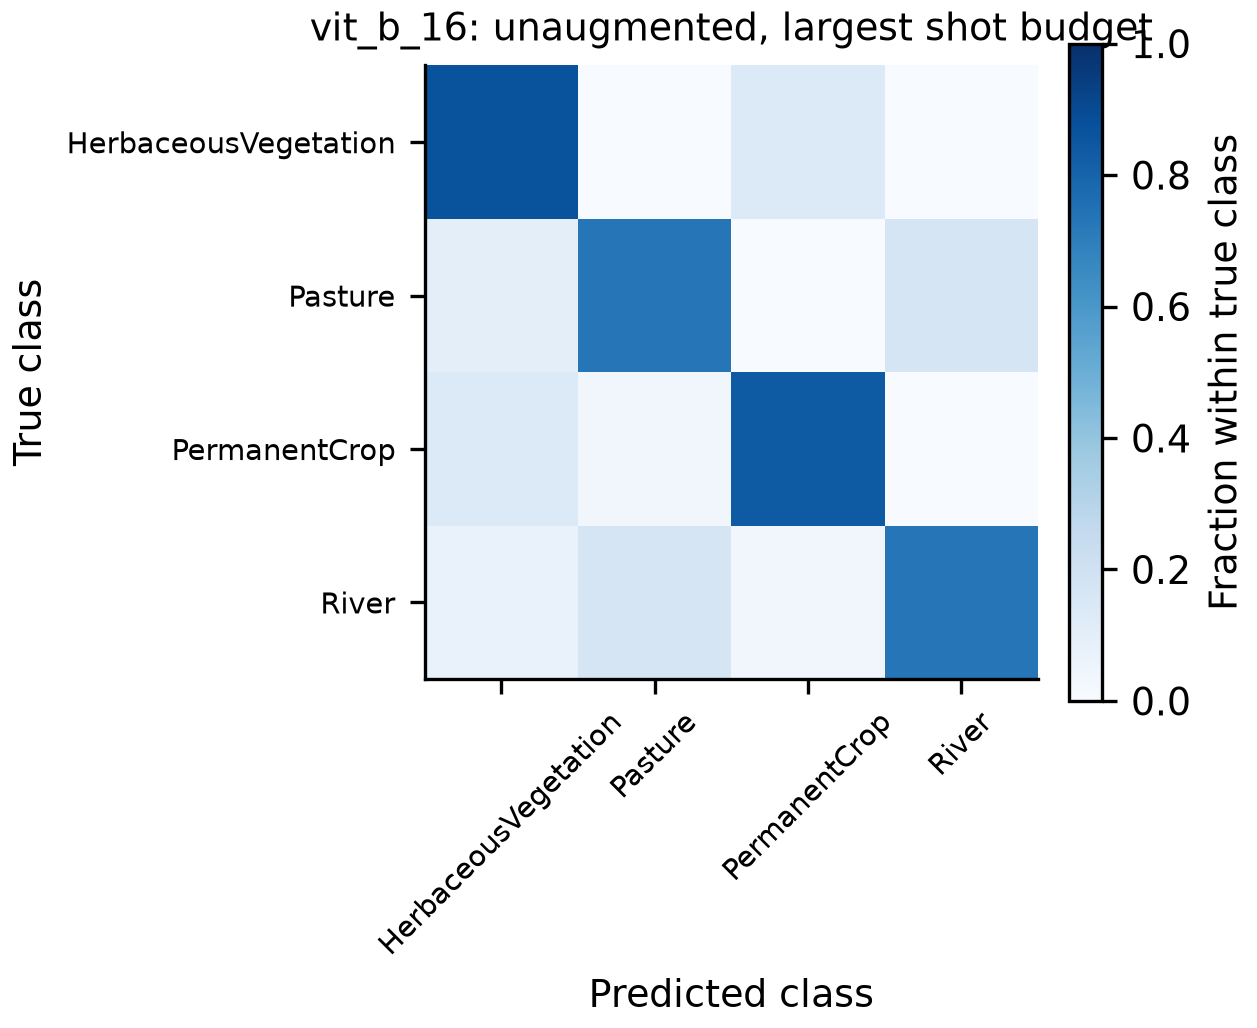

In [12]:
display_model_evaluation(results, 'vit_b_16')


### 6.4 DINOv2 ViT-S/14

A self-supervised representation. Differences also include pretraining data and model size, not only the learning objective.

,,accuracy,macro_f1,episodes,dev_accuracy,selected_C,mean_fit_seconds
shots,policy,,,,,,
1,none,0.5667,0.5743,2,0.6417,1.0,0.0009
5,none,0.7583,0.7618,2,0.7750,10.0,0.0024
10,none,0.8500,0.8486,2,0.8000,10.0,0.0026


,class_recall
HerbaceousVegetation,1.0000
Pasture,0.8000
PermanentCrop,0.8333
River,0.7667


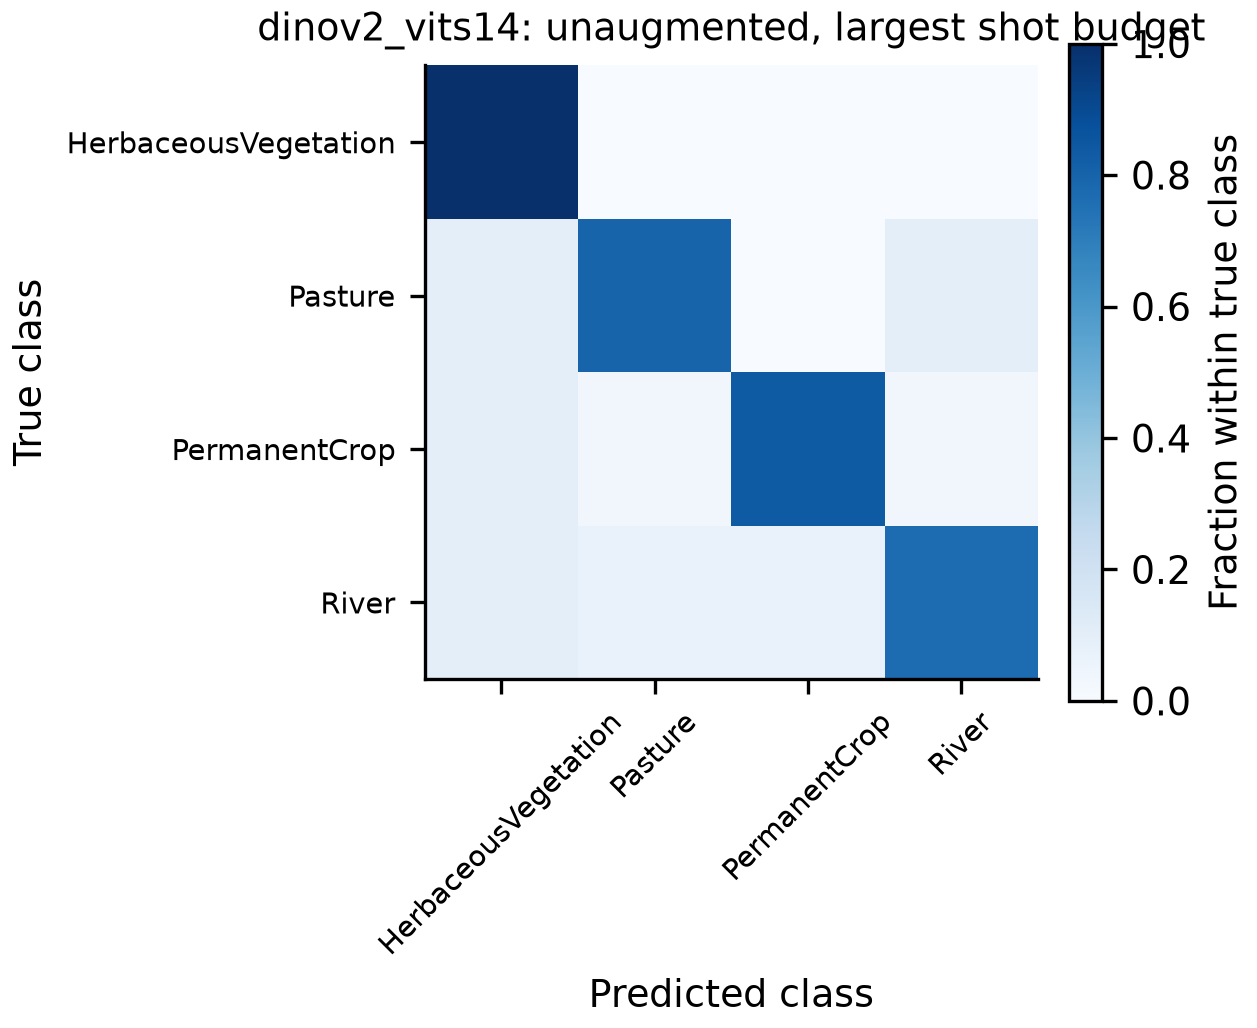

In [13]:
display_model_evaluation(results, 'dinov2_vits14')


## 7. Compare all models with the ResNet baseline

Accuracy/Macro-F1 are fractions. Differences from ResNet are **paired percentage points** using matching policy, shot and episode IDs. ResNet rows have zero paired gain by definition. If ResNet was not selected, this table shows scores only and does not claim a baseline gain.

Images recur across episodes, so variability and bootstrap intervals describe this fixed sampling schedule; they do not establish geographic generalization. Review negative as well as positive effects. Full results require the deliberate full episode budget.


,model,policy,shots,accuracy,macro_f1,episodes,accuracy_gain_vs_resnet_pp,macro_f1_gain_vs_resnet_pp
0,convnext_tiny,none,1,0.6333,0.6230,2,1.6667,2.4302
1,convnext_tiny,none,5,0.9000,0.9026,2,-0.8333,-0.7068
2,convnext_tiny,none,10,0.8250,0.8255,2,-1.6667,-1.6684
3,dinov2_vits14,none,1,0.5667,0.5743,2,-5.0000,-2.4445
4,dinov2_vits14,none,5,0.7583,0.7618,2,-15.0000,-14.7868
5,dinov2_vits14,none,10,0.8500,0.8486,2,0.8333,0.6415
6,resnet18,none,1,0.6167,0.5987,2,0.0000,0.0000
7,resnet18,none,5,0.9083,0.9097,2,0.0000,0.0000
8,resnet18,none,10,0.8417,0.8422,2,0.0000,0.0000
9,vit_b_16,none,1,0.6667,0.6575,2,5.0000,5.8799


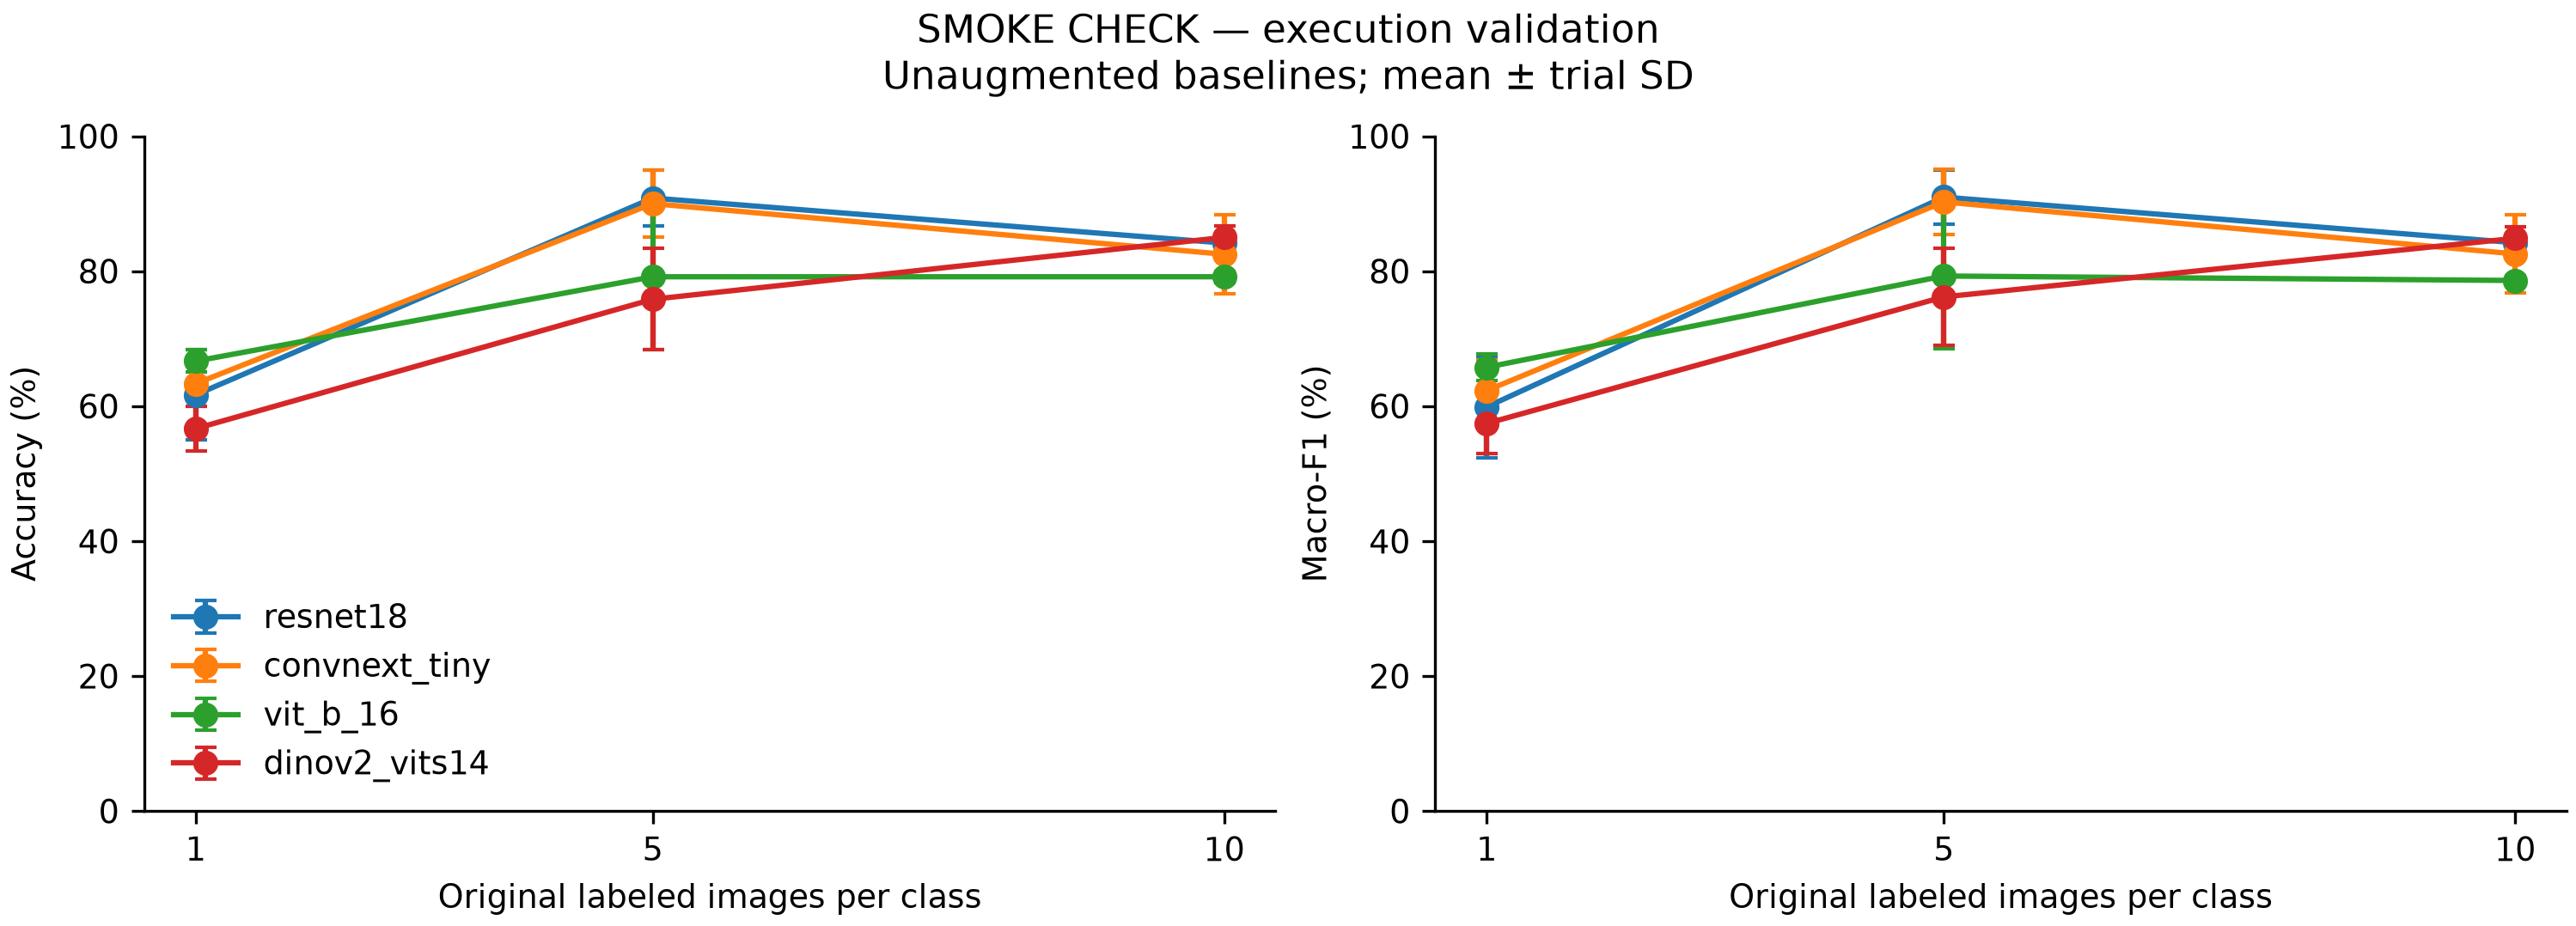

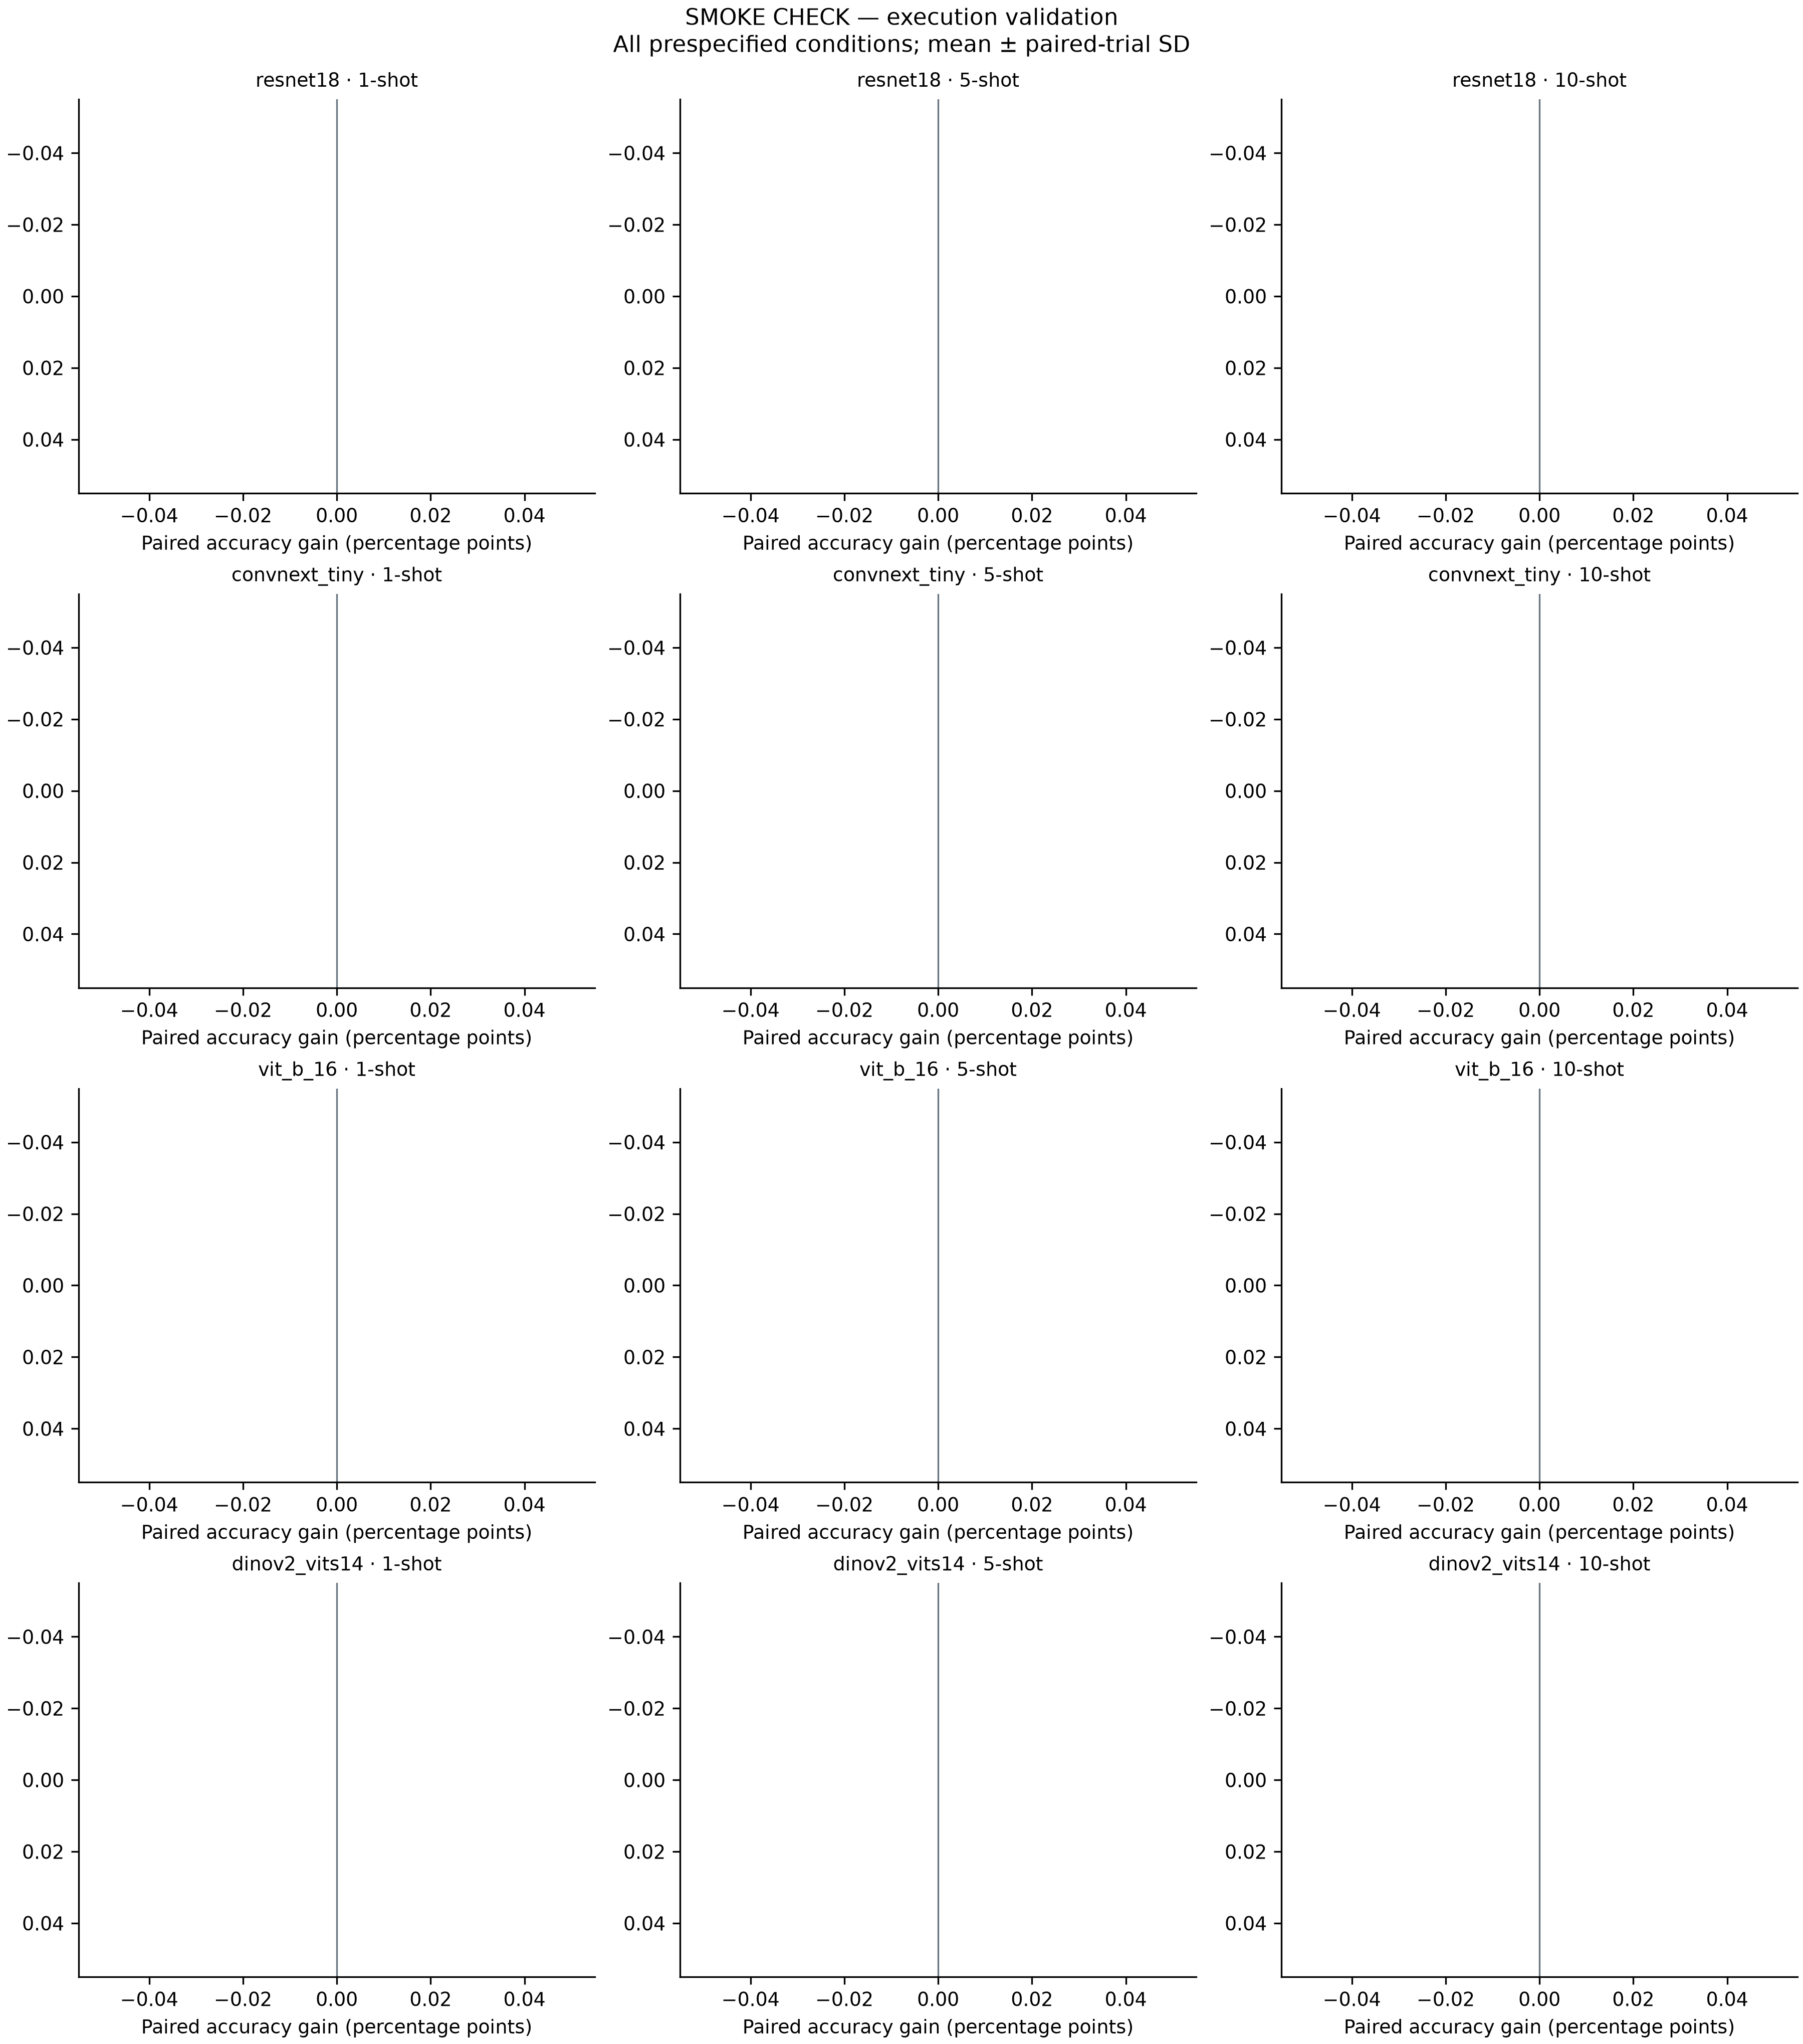

Combined figures, class metrics, timing tables and provenance: /Users/ericsheng495/Desktop/eurosat-representation-benchmark/outputs/7b7f585609eb29506decccd73d70807375d37948e81b7542996ac98734f81488/report


In [14]:
display(baseline_comparison(results).round(4))

report = results['report']
for name in ['model_by_shot', 'augmentation_gains']:
    display(NotebookImage(filename=report['figures'][name], width=1000))

print('Combined figures, class metrics, timing tables and provenance:', report['output'])
